In [1]:
from sklearn.feature_selection import SelectKBest, mutual_info_regression  # Para la selección de características
from sklearn.ensemble import RandomForestRegressor  # Modelo de Random Forest
from sklearn.model_selection import cross_val_score
import pandas as pd  # Para manipulación de datos
import matplotlib.pyplot as plt  # Para visualización
import seaborn as sns  # Para gráficos más estilizados
import numpy as np
import os

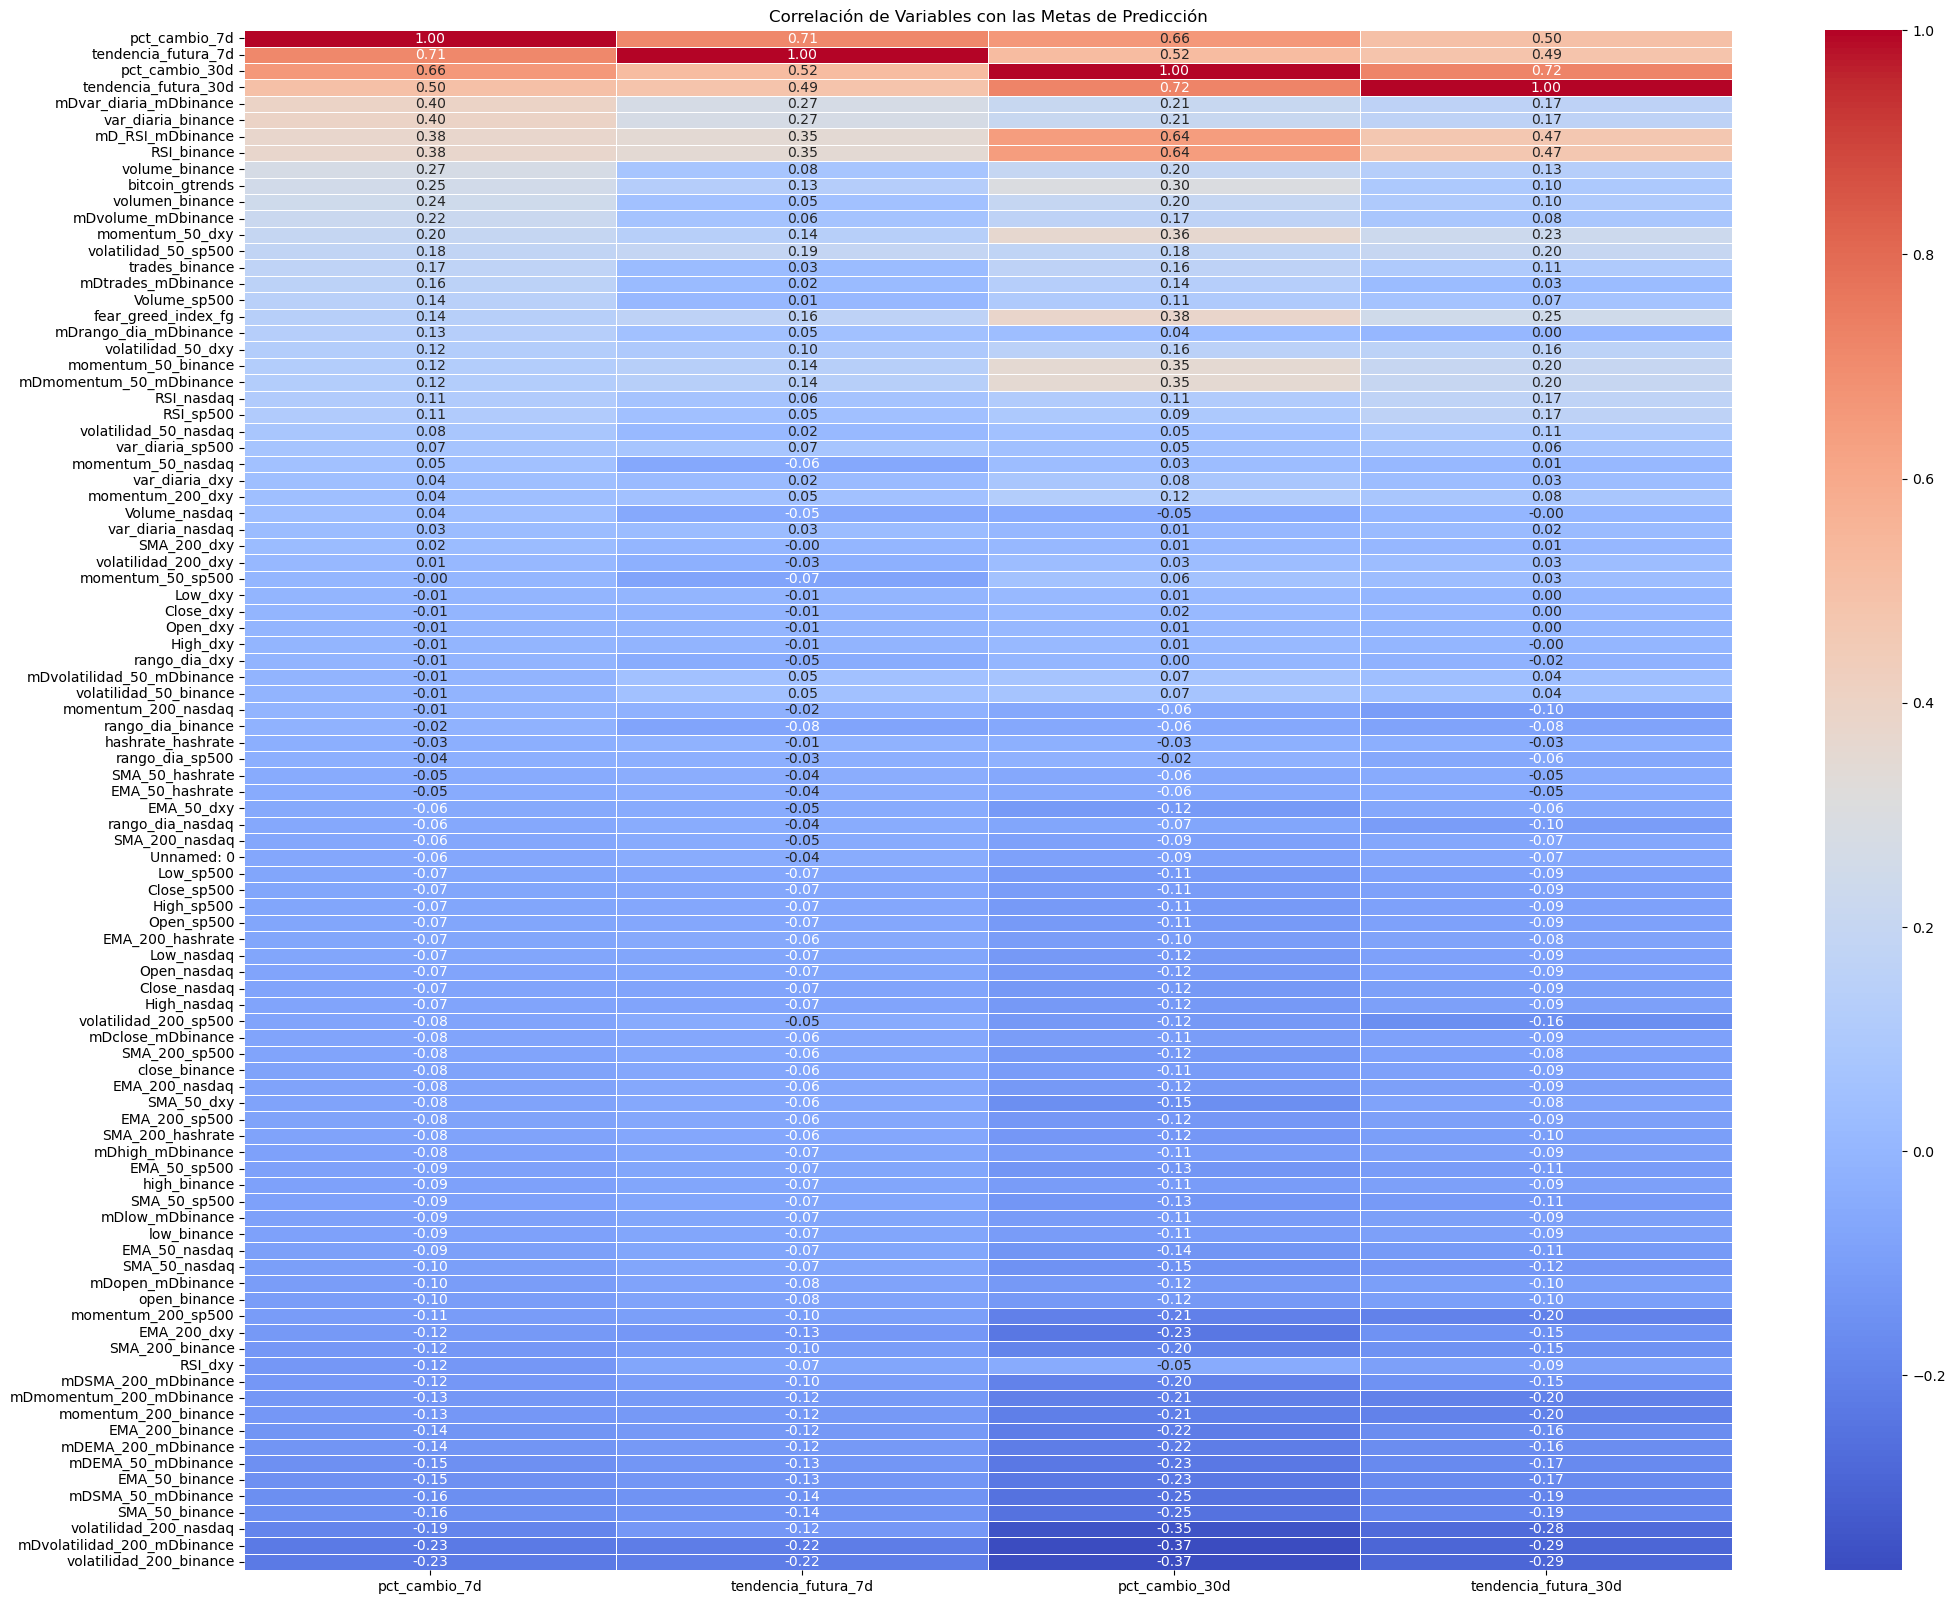

In [2]:
# Cargar los datos
csv_file_path = r"../../data/limpieza/cleaned_data.csv"
df_timestamp = pd.read_csv(csv_file_path)

df = df_timestamp.drop('timestamp', axis=1)

# Calcular la correlación con las variables objetivo
corr_target = df.corr()[['pct_cambio_7d', 'tendencia_futura_7d', 'pct_cambio_30d', 'tendencia_futura_30d']].sort_values(by='pct_cambio_7d', ascending=False)

# Mostrar las variables más correlacionadas con las metas
plt.figure(figsize=(24, 20))
sns.heatmap(corr_target, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlación de Variables con las Metas de Predicción")
plt.show()

Variables seleccionadas tras Mutual Information: ['SMA_200_dxy', 'bitcoin_gtrends', 'volatilidad_50_binance', 'volatilidad_50_sp500', 'mDSMA_50_mDbinance', 'volatilidad_200_nasdaq', 'EMA_50_dxy', 'RSI_binance', 'RSI_dxy', 'RSI_sp500']

Importancia de variables según Random Forest:
                 Variable  Importancia
1         bitcoin_gtrends     0.209869
7             RSI_binance     0.140218
2  volatilidad_50_binance     0.123535
5  volatilidad_200_nasdaq     0.104027
4      mDSMA_50_mDbinance     0.097954
0             SMA_200_dxy     0.091770
3    volatilidad_50_sp500     0.073979
6              EMA_50_dxy     0.069354
9               RSI_sp500     0.044731
8                 RSI_dxy     0.044563


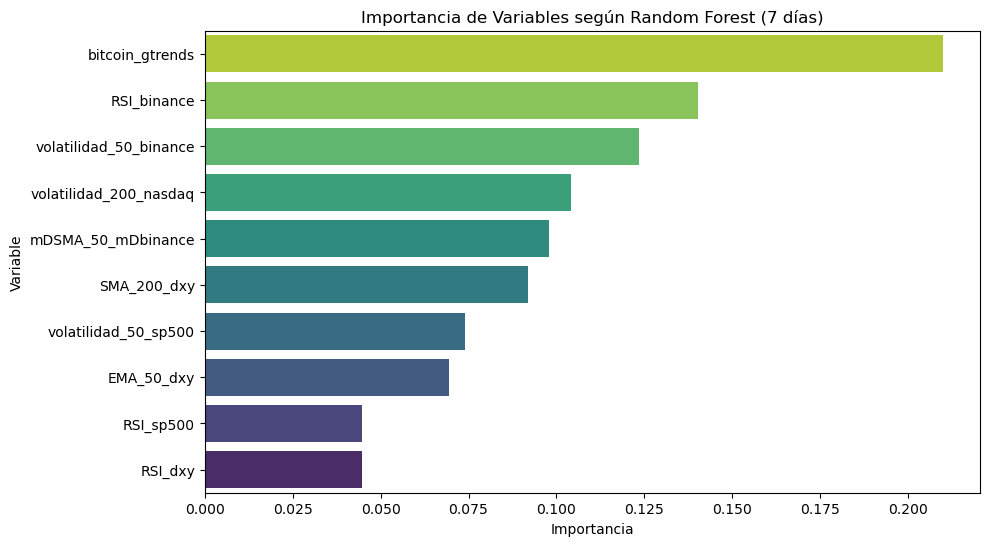

In [3]:
# Lo que haremos en este código es realizar una selección de variables utilizando la información mutua (Mutual Information), 
# para identificar las características más relevantes para predecir el cambio porcentual de 7 días ('pct_cambio_7d').
# Luego, utilizaremos un modelo de RandomForestRegressor para confirmar la importancia de las variables seleccionadas.
# Finalmente, visualizaremos las importancias de las variables seleccionadas a través de un gráfico de barras.

# 🔹 Definir la variable objetivo
target_7d = "pct_cambio_7d"

# 🔹 Definir las variables explicativas
features = [
 'mDSMA_50_mDbinance',
 'EMA_50_dxy',
 'SMA_200_dxy',
 'mDmomentum_50_mDbinance',
 'momentum_200_binance',
 'momentum_50_sp500',
 'momentum_200_dxy',
 'momentum_50_dxy',
 'volatilidad_50_binance',
 'volatilidad_50_sp500',
 'volatilidad_200_nasdaq',
 'volatilidad_50_dxy',
 'RSI_binance',
 'RSI_sp500',
 'RSI_dxy',
 'var_diaria_binance',
 'mDrango_dia_mDbinance',
 'volumen_binance',
 'mDvolume_mDbinance',
 'fear_greed_index_fg',
 'bitcoin_gtrends',
]  # Lista de características para el modelo

# 🔹 Definir las características (X) y el target (y)
X_7d = df[features]  # Variables explicativas
y_7d = df[target_7d]  # Variable objetivo

### 📌 PASO 1: SELECCIÓN INICIAL CON MUTUAL INFORMATION ###
selector = SelectKBest(mutual_info_regression, k="all")  # Evaluamos todas las variables
selector.fit(X_7d, y_7d)  # Ajustamos el selector a los datos
mi_scores = selector.scores_  # Extraemos los puntajes de información mutua

# Crear DataFrame con los resultados
mi_df = pd.DataFrame({"Variable": features, "MI_Score": mi_scores})
mi_df = mi_df.sort_values(by="MI_Score", ascending=False)  # Ordenamos de mayor a menor

# Filtrar variables
umbral = mi_df["MI_Score"].median()  

# Usamos como umbral de selección la mediana porque es más robusta a valores extremos o atípicos.
# En la predicción a 7 días, buscamos identificar las variables más consistentes en su relevancia,
# evitando que valores muy altos o muy bajos de información mutua distorsionen la selección.
# La mediana nos ayuda a establecer un umbral equilibrado, descartando variables menos relevantes.

selected_features = mi_df[mi_df["MI_Score"] > umbral]["Variable"].tolist()
print(f"Variables seleccionadas tras Mutual Information: {selected_features}")

### 📌 PASO 2: CONFIRMAR IMPORTANCIA CON RANDOM FOREST ###
rf = RandomForestRegressor(n_estimators=200, random_state=42)  # Modelo con 200 árboles
rf.fit(X_7d[selected_features], y_7d)  # Entrenamos el modelo con las características seleccionadas

# Obtener importancia de variables
importances = rf.feature_importances_
importance_df = pd.DataFrame({"Variable": selected_features, "Importancia": importances})
importance_df = importance_df.sort_values(by="Importancia", ascending=False)

print("\nImportancia de variables según Random Forest:")
print(importance_df)

# 🔹 Visualización de las importancias
# Ordenar el DataFrame de importancia de menor a mayor para mejor visualización
importance_df = importance_df.sort_values(by="Importancia", ascending=True)

# Crear la gráfica de barras horizontales
plt.figure(figsize=(10, 6))
sns.barplot(x="Importancia", y="Variable", data=importance_df, hue="Variable", palette="viridis", legend=False)
plt.title("Importancia de Variables según Random Forest (7 días)")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.gca().invert_yaxis()  # Para que las más importantes aparezcan arriba
plt.show()

In [4]:
df_respuesta_7d = df_timestamp[['timestamp','volatilidad_50_sp500', 'SMA_200_dxy', 'EMA_50_dxy', 
                      'mDSMA_50_mDbinance', 'volatilidad_50_binance', 'volatilidad_50_dxy', 
                      'volatilidad_200_nasdaq', 'momentum_200_dxy', 'RSI_binance', 'momentum_50_dxy', 
                      'tendencia_futura_7d', 'pct_cambio_7d']
] #añadimos las variables respuesta a las seleccionadas por MI

output_path = r"../../data/limpieza/dataset_7d.csv"
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_respuesta_7d.to_csv(output_path, index=False)

Variables seleccionadas tras Mutual Information: ['volatilidad_200_nasdaq', 'SMA_200_dxy', 'mDSMA_50_mDbinance', 'EMA_50_dxy', 'volatilidad_50_nasdaq', 'bitcoin_gtrends', 'volatilidad_50_dxy', 'momentum_200_dxy', 'mDvolatilidad_50_mDbinance', 'momentum_50_nasdaq', 'momentum_50_dxy']

Importancia de variables según Random Forest:
                      Variable  Importancia
0       volatilidad_200_nasdaq     0.380494
10             momentum_50_dxy     0.152489
3                   EMA_50_dxy     0.108997
2           mDSMA_50_mDbinance     0.092916
1                  SMA_200_dxy     0.066299
5              bitcoin_gtrends     0.066126
7             momentum_200_dxy     0.049868
6           volatilidad_50_dxy     0.025454
4        volatilidad_50_nasdaq     0.022648
9           momentum_50_nasdaq     0.021213
8   mDvolatilidad_50_mDbinance     0.013496


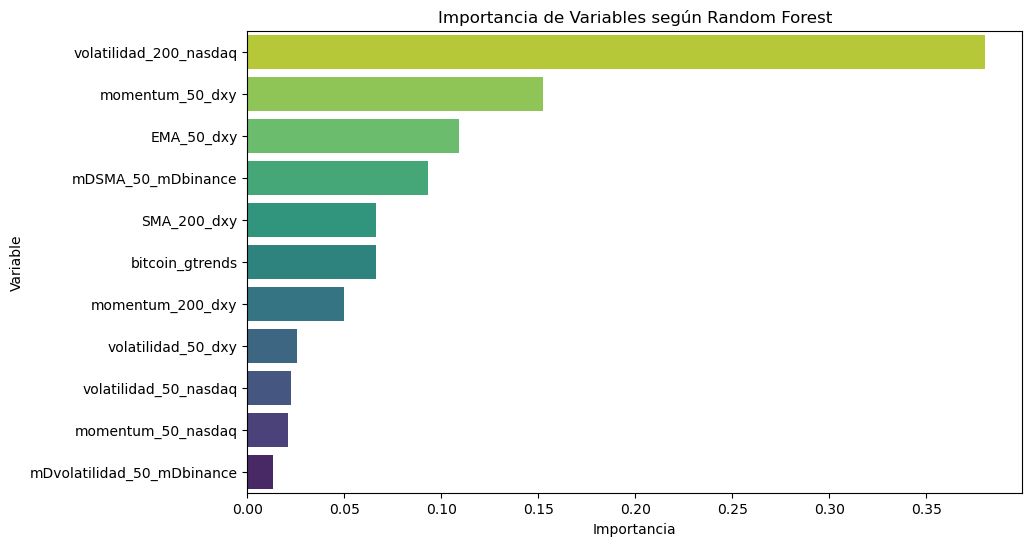

In [5]:
# Lo que haremos en este código es realizar una selección de variables utilizando la información mutua (Mutual Information), 
# para identificar las características más relevantes para predecir el cambio porcentual de 30 días ('pct_cambio_30d').
# Luego, utilizaremos un modelo de RandomForestRegressor para confirmar la importancia de las variables seleccionadas.
# Finalmente, visualizaremos las importancias de las variables seleccionadas a través de un gráfico de barras.

# 🔹 Definir la variable objetivo
target_30d = "pct_cambio_30d"

# 🔹 Definir las variables explicativas
features = [
 'mDSMA_50_mDbinance',
 'EMA_50_dxy',
 'SMA_200_dxy',
 'mDmomentum_50_mDbinance',
 'momentum_200_binance',
 'momentum_50_nasdaq',
 'momentum_200_dxy',
 'momentum_50_dxy',
 'mDvolatilidad_50_mDbinance',
 'volatilidad_50_nasdaq',
 'volatilidad_200_nasdaq',
 'volatilidad_50_dxy',
 'RSI_binance',
 'RSI_nasdaq',
 'RSI_dxy',
 'mDvar_diaria_mDbinance',
 'mDrango_dia_mDbinance',
 'trades_binance',
 'mDvolume_mDbinance',
 'fear_greed_index_fg',
 'bitcoin_gtrends'
]

# 🔹 Definir las características (X) y el target (y)
X_30d = df[features]
y_30d = df[target_30d]

### 📌 PASO 1: SELECCIÓN INICIAL CON MUTUAL INFORMATION ###
selector = SelectKBest(mutual_info_regression, k="all")  # Evaluamos todas las variables
selector.fit(X_30d, y_30d)
mi_scores = selector.scores_

# Crear DataFrame con los resultados
mi_df = pd.DataFrame({"Variable": features, "MI_Score": mi_scores})
mi_df = mi_df.sort_values(by="MI_Score", ascending=False)

# Filtrar variables
umbral = mi_df["MI_Score"].mean() 

# Usamos como umbral de selección la media porque en la predicción a 30 días queremos considerar 
# una mayor cantidad de variables que puedan aportar información, incluso si algunas tienen valores 
# de importancia más altos o más bajos. La media permite capturar más señales al promediar todas 
# las puntuaciones de información mutua, lo que puede ser útil para tendencias a más largo plazo.

selected_features = mi_df[mi_df["MI_Score"] > umbral]["Variable"].tolist()
print(f"Variables seleccionadas tras Mutual Information: {selected_features}")

### 📌 PASO 2: CONFIRMAR IMPORTANCIA CON RANDOM FOREST ###
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_30d[selected_features], y_30d)

# Obtener importancia de variables
importances = rf.feature_importances_
importance_df = pd.DataFrame({"Variable": selected_features, "Importancia": importances})
importance_df = importance_df.sort_values(by="Importancia", ascending=False)

print("\nImportancia de variables según Random Forest:")
print(importance_df)

# Ordenar el DataFrame de importancia
importance_df = importance_df.sort_values(by="Importancia", ascending=True)

# Crear la gráfica de barras
plt.figure(figsize=(10, 6))
sns.barplot(x="Importancia", y="Variable", data=importance_df, hue="Variable", palette="viridis", legend=False)
plt.title("Importancia de Variables según Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.gca().invert_yaxis()
plt.show()

In [6]:
df_respuesta_30d = df_timestamp[['timestamp','volatilidad_200_nasdaq', 'EMA_50_dxy', 'mDSMA_50_mDbinance', 'SMA_200_dxy', 
                       'volatilidad_50_dxy', 'volatilidad_50_nasdaq', 'momentum_200_dxy', 'mDvolatilidad_50_mDbinance', 
                       'momentum_50_dxy', 'tendencia_futura_30d', 'pct_cambio_30d']
                     ]  #añadimos las variables respuesta a las seleccionadas por MI

output_path = r"../../data/limpieza/dataset_30d.csv"
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_respuesta_30d.to_csv(output_path, index=False)